# Arrays and Matrix Calculus: Derivatives with Computational Meaning

## 1. Introduction and learning objectives

Calculus knowledge becomes useful in ML only when a derivative has the right meaning, shape, reduction, and numerical value. A correct scalar chain rule can still become an incorrect program when a target silently broadcasts across observations or a loss average appears twice.

This applied chapter assumes multivariable calculus, matrix multiplication, and Python. You will translate differentials into array gradients, distinguish a full Jacobian from its products with vectors, inspect curvature, and check derivatives without automatic differentiation. It introduces no fitted ML model.

Use the first three exercises as a diagnostic. For these questions, examples are rows; a Jacobian has **output coordinates as rows and input coordinates as columns**. NumPy broadcasting compares dimensions from the right: dimensions must be equal or one. Missing leading dimensions behave as one. A gradient collects derivatives of a scalar, while a Jacobian describes a vector-valued map.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 00.01.01 — Trace an affine batch

**Type:** Conceptual · **Answer:** Markdown

For $X:(4,3)$, $W:(3,2)$, and $b:(2,)$, state the shapes of $Z=XW+b$ and a sensitivity $G=\partial J/\partial Z$. Explain which axis a bias gradient must sum over.

**Expected outcome:** A forward/reverse shape trace and an explanation of parameter reuse.

**Your response to Exercise 00.01.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.01**

The same two bias entries are used for each of four observations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.01**

$Z$ and $G$ both have shape $(4,2)$. A change in bias entry $b_j$ changes $Z_{ij}$ by the same amount for every observation $i$, so $\partial J/\partial b_j=\sum_iG_{ij}$. Summing axis zero returns $(2,)$; summing columns would return $(4,)$, one value per observation rather than per bias.

</details>

### Exercise 00.01.02 — Expose accidental broadcasting

**Type:** Numerical · **Answer:** Markdown

Predictions are stored as `[[1.0], [2.0]]` and targets as `[1.0, 2.0]`. Calculate the subtraction's full array and its mean squared value. Compare it to correctly paired residuals.

**Expected outcome:** The incorrect shape and four entries, and the correct two residuals.

**Your response to Exercise 00.01.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.02**

A column minus a one-dimensional vector creates one comparison for every row/column pair.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.02**

The subtraction broadcasts to $(2,2)$:
$$
\begin{bmatrix}1\\2\end{bmatrix}-
\begin{bmatrix}1&2\end{bmatrix}
=\begin{bmatrix}0&-1\\1&0\end{bmatrix}.
$$
Its mean squared value is $2/4=1/2$, although the correctly paired predictions are perfect. Using two arrays of shape $(2,)$ or two of shape $(2,1)$ gives residuals zero. A finite scalar loss therefore does not establish that observations were paired correctly.

</details>

### Exercise 00.01.03 — Compute both Jacobian products

**Type:** Mathematical · **Answer:** Markdown

Let $f(t_1,t_2)=(t_1^2+t_2,\ t_1t_2)^T$. At $t=(2,3)^T$, calculate its Jacobian, the JVP for $v=(1,-1)^T$, and the VJP for output seed $u=(2,-1)^T$.

**Expected outcome:** Three explicit arrays with dimensions and the directional meaning of each product.

**Your response to Exercise 00.01.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.03**

A JVP is $J_fv$; the column representation of a VJP is $J_f^Tu$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.03**

$$
J_f(t)=\begin{bmatrix}2t_1&1\\t_2&t_1\end{bmatrix},
\quad J_f(2,3)=\begin{bmatrix}4&1\\3&2\end{bmatrix}.
$$
Thus $J_fv=(3,1)^T$ is the first-order change in the two outputs along input direction $v$. The reverse product is $J_f^Tu=(5,0)^T$, the gradient of the scalar $u^Tf(t)$ with respect to its two inputs. The vectors happen to have the same length here; they belong to different input/output spaces in general.

</details>

## 2. Prerequisites and mathematical foundations

### Shapes encode the mathematical contract

For $n$ examples, $d$ inputs, and $m$ outputs, $X\in\mathbb R^{n\times d}$, $W\in\mathbb R^{d\times m}$, and $Z\in\mathbb R^{n\times m}$. Store a repeated bias as a one-dimensional $(m,)$ array. A mathematical column vector and a NumPy one-dimensional array are different representations; state the choice before subtracting or multiplying.

Broadcasting describes repeated use, not an independent new parameter at every repeated position. Consequently, reversing a broadcast requires summing sensitivities over the repeated positions. Copies and views are another distinction: a cached parameter view can change when an optimizer updates its original array. Differentiate at one unchanged state, or cache a copy where needed.

### Jacobians, directional derivatives, and scalarization

For $f:\mathbb R^d\to\mathbb R^m$, define $(J_f)_{ij}=\partial f_i/\partial x_j$, shape $(m,d)$. A small perturbation obeys
$$
f(x+\Delta)\approx f(x)+J_f(x)\Delta.
$$
The JVP $J_fv$ asks how outputs respond along input direction $v$. If a scalar objective already supplies output sensitivity $u$, the chain rule gives $\nabla_xJ=J_f^Tu$. One scalar loss therefore needs a reverse product, not a stored dense Jacobian for every operation. A composition gives $J_{g\circ f}=J_gJ_f$; reverse products apply the transposes in the opposite order.

The Frobenius inner product is $\langle A,B\rangle_F=\sum_{ij}A_{ij}B_{ij}=\operatorname{tr}(A^TB)$. Defining $\nabla_WJ$ by $dJ=\langle\nabla_WJ,dW\rangle_F$ fixes its shape and meaning without memorizing a table of matrix derivatives.

## 3. Theoretical development and worked examples

### Reverse an affine map using differentials

For $Z=XW+\mathbf1_nb^T$, a perturbation is
$$
dZ=dX\,W+X\,dW+\mathbf1_n\,db^T.
$$
Given $G=\partial J/\partial Z$, substitute this into $dJ=\operatorname{tr}(G^TdZ)$. Cycling compatible factors inside a trace identifies
$$
\nabla_XJ=GW^T,\qquad
\nabla_WJ=X^TG,\qquad
\nabla_bJ=\sum_{\text{rows}}G.
$$
Their shapes are $(n,d)$, $(d,m)$, and $(m,)$. Each sum corresponds to the same parameter influencing multiple computations. The supplied $G$ already contains any loss normalization; these local rules introduce no additional average.

**Worked calculation.** Let $X=\begin{bmatrix}1&2\\-1&0\end{bmatrix}$, $W=(2,-1)^T$, $b=1$, and $G=(1/2,-1/2)^T$. Then $Z=(1,-1)^T$, $X^TG=(1,1)^T$, $\sum_iG_i=0$, and $GW^T=\begin{bmatrix}1&-1/2\\-1&1/2\end{bmatrix}$. The sensitivity is given; it need not equal the predictions.

### Exercise 00.01.04 — Derive a squared matrix objective

**Type:** Mathematical · **Answer:** Markdown

For fixed $A:(n,d)$ and $Y:(n,m)$, let $R=AW+b-Y$ and $J=\|R\|_F^2/(2n)$. Derive the weight and bias gradients using a differential. Explain why dividing by $nm$ would change them.

**Expected outcome:** A derivation with a specified reduction rather than a shape-only answer.

**Your response to Exercise 00.01.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.04**

The sensitivity to $R$ is $R/n$ for the stated objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.04**

Since $d\|R\|_F^2=2\langle R,dR\rangle_F$, we have $dJ=\langle R/n,A\,dW+\mathbf1_n\,db^T\rangle_F$. Therefore $\nabla_WJ=A^TR/n$ and $\nabla_bJ=\sum_iR_{i,:}/n$. The objective averages the sum of squared output errors per observation. Averaging all $nm$ entries instead would shrink both gradients by $m$ and define a different loss convention.

</details>

### Curvature without constructing every second derivative

For symmetric $Q$, a quadratic
$$
J(t)=\frac12t^TQt-r^Tt
$$
has gradient $Qt-r$ and Hessian $Q$. Symmetry matters: an arbitrary $Q$ gives gradient $(Q+Q^T)t/2-r$. Positive definiteness makes the quadratic strictly convex. The local second-order approximation is $J(t+\Delta)\approx J(t)+g^T\Delta+\Delta^TH\Delta/2$.

A Hessian-vector product is $Hv$, which can be checked by differentiating the gradient along $v$:
$$
Hv\approx\frac{\nabla J(t+hv)-\nabla J(t-hv)}{2h}.
$$
This directional calculation avoids materializing a $d\times d$ Hessian. It is a numerical check, not an exact symbolic identity for finite $h$.

### Exercise 00.01.05 — Evaluate a quadratic state

**Type:** Numerical · **Answer:** Markdown

Use $Q=\begin{bmatrix}2&1\\1&3\end{bmatrix}$, $r=(1,-1)^T$, $t=(1,2)^T$, and $v=(1,-1)^T$. Calculate the loss, gradient, and Hessian-vector product.

**Expected outcome:** One scalar and two vectors with intermediate products.

**Your response to Exercise 00.01.05**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.05**

Compute $Qt$ before subtracting $r$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.05**

$Qt=(4,7)^T$ and $r^Tt=-1$, so $J=(4+14)/2-(-1)=10$. The gradient is $(4,7)^T-(1,-1)^T=(3,8)^T$. Finally $Qv=(1,-2)^T$. The Hessian is constant for this quadratic; its product is independent of the evaluation point even though the gradient is not.

</details>

## 4. Guided exercises

### Numerical checks have a domain and a scale

Central differences perturb a coordinate or a declared direction while holding all other inputs fixed. Smoothness gives an approximation error typically of order $h^2$ locally; roundoff and cancellation grow important when $h$ is too small. Compare both maximum absolute error and relative norm error, with a denominator floor when gradients nearly vanish.

Check several points, batch sizes, and perturbations. A derivative test at a stationary point can pass a missing-path implementation because both the correct and incorrect contributions happen to be zero. Non-smooth corners need separate conventions and tests.

### Exercise 00.01.06 — Locate the observation average

**Type:** Conceptual · **Answer:** Markdown

An objective averages observations but sums its output coordinates. Its output sensitivity already divides by $n$. Should an affine weight gradient or bias sum divide by $n$ again? What happens if only weights receive the extra division?

**Expected outcome:** A precise normalization diagnosis, including the effect on relative weight/bias updates.

**Your response to Exercise 00.01.06**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.06**

The local affine rule propagates the sensitivity it was given.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.06**

Neither operation divides again. The weight product and bias sum already combine entries carrying $1/n$. Another division gives $1/n^2$ data scaling. If applied only to weights, it shrinks their updates relative to bias updates, so changing one global learning rate cannot restore the original gradient. A direct weight penalty can further change the relative data/penalty strength.

</details>

## 5. Implementation challenges

Implement small functions with explicit shape and finite-value checks. Return arrays rather than modifying parameters. The displayed references are optional comparisons, and do not run with the notebook.

### Exercise 00.01.07 — Implement an affine VJP

**Type:** Programming · **Answer:** Code

Write a function returning $Z$, $\nabla_XJ$, $\nabla_WJ$, and $\nabla_bJ$ for a supplied output sensitivity. Reject malformed shapes and nonfinite arrays. Include a one-example, multiple-output check.

**Expected outcome:** A reusable local rule with no hidden loss normalization or parameter mutation.

In [ ]:
# Your code for Exercise 00.01.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.07**

Validate the output sensitivity against $(n,m)$ before multiplying.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.07**

This reference uses the differential rules directly. The caller, not this function, chooses the scalar objective and its normalization.

~~~python
def affine_vjp(X, W, b, G):
    X, W, b, G = [np.asarray(a, dtype=float) for a in (X, W, b, G)]
    if X.ndim != 2 or W.ndim != 2 or min(X.shape) == 0 or min(W.shape) == 0:
        raise ValueError("X and W must be nonempty matrices")
    if W.shape[0] != X.shape[1] or b.shape != (W.shape[1],):
        raise ValueError("feature or bias shape mismatch")
    if G.shape != (X.shape[0], W.shape[1]):
        raise ValueError("G must match the affine output")
    if not all(np.isfinite(a).all() for a in (X, W, b, G)):
        raise ValueError("all arrays must be finite")
    return X @ W + b, G @ W.T, X.T @ G, G.sum(axis=0)

reference_X = np.array([[1., 2.], [-1., 0.]])
reference_W = np.array([[2.], [-1.]])
reference_result = affine_vjp(reference_X, reference_W, [1.], [[.5], [-.5]])
np.testing.assert_allclose(reference_result[0], [[1.], [-1.]])
np.testing.assert_allclose(reference_result[2], [[1.], [1.]])
np.testing.assert_allclose(reference_result[3], [0.])
~~~

</details>

### Exercise 00.01.08 — Check a full Jacobian

**Type:** Programming · **Answer:** Code

Implement a central-difference Jacobian for a finite vector-valued function of a one-dimensional parameter vector. Preserve the input and verify output shapes at every perturbation.

**Expected outcome:** An $(m,d)$ numerical Jacobian agreeing with the diagnostic example.

In [ ]:
# Your code for Exercise 00.01.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.08**

Each perturbed input coordinate produces one Jacobian column.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.08**

This function evaluates a fresh input copy for every call. Its positive step is absolute; scaling parameters may require changing that step.

~~~python
def finite_jacobian(function, x, step=1e-5):
    x = np.asarray(x, dtype=float)
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("x must be a nonempty finite vector")
    if not np.isfinite(step) or step <= 0:
        raise ValueError("step must be finite and positive")
    baseline = np.asarray(function(x.copy()), dtype=float)
    if baseline.ndim != 1 or baseline.size == 0 or not np.isfinite(baseline).all():
        raise ValueError("function must return a finite vector")
    result = np.empty((baseline.size, x.size))
    for j in range(x.size):
        plus, minus = x.copy(), x.copy()
        plus[j] += step
        minus[j] -= step
        p, m = np.asarray(function(plus), float), np.asarray(function(minus), float)
        if p.shape != baseline.shape or m.shape != baseline.shape:
            raise ValueError("function output shape changed")
        if not (np.isfinite(p).all() and np.isfinite(m).all()):
            raise ValueError("nonfinite perturbed output")
        result[:, j] = (p - m) / (2 * step)
    return result

reference_function = lambda t: np.array([t[0]**2 + t[1], t[0] * t[1]])
np.testing.assert_allclose(
    finite_jacobian(reference_function, [2., 3.]), [[4., 1.], [3., 2.]],
    rtol=1e-7, atol=1e-8,
)
~~~

</details>

### Exercise 00.01.09 — Check a JVP without a Jacobian

**Type:** Programming · **Answer:** Code

Implement a directional central difference returning $J_fv$ without constructing all columns. State whether your direction is normalized.

**Expected outcome:** The diagnostic JVP and an agreement check with a full Jacobian product.

In [ ]:
# Your code for Exercise 00.01.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.09**

Perturb the entire vector by plus/minus $hv$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.09**

This uses the full-vector convention of the preceding exercise but is independently implemented. It does not normalize $v$: changing its length changes the requested directional derivative.

~~~python
def directional_jvp(function, x, v, step=1e-5):
    x, v = np.asarray(x, float), np.asarray(v, float)
    if x.ndim != 1 or x.size == 0 or v.shape != x.shape:
        raise ValueError("x and v must be equally shaped nonempty vectors")
    if not all(np.isfinite(a).all() for a in (x, v)) or not np.isfinite(step) or step <= 0:
        raise ValueError("finite inputs and positive step required")
    plus = np.asarray(function((x + step * v).copy()), float)
    minus = np.asarray(function((x - step * v).copy()), float)
    if plus.ndim != 1 or plus.size == 0 or plus.shape != minus.shape:
        raise ValueError("function must return matching vectors")
    if not (np.isfinite(plus).all() and np.isfinite(minus).all()):
        raise ValueError("nonfinite output")
    return (plus - minus) / (2 * step)

# Uses reference_function and finite_jacobian from 00.01.08.
reference_v = np.array([1., -1.])
np.testing.assert_allclose(
    directional_jvp(reference_function, [2., 3.], reference_v), [3., 1.],
    rtol=1e-7, atol=1e-8,
)
~~~

</details>

### Exercise 00.01.10 — Check a Hessian-vector product

**Type:** Programming · **Answer:** Code

Use a gradient function to implement a numerical HVP. Verify the quadratic example without constructing a Hessian inside the implementation.

**Expected outcome:** A parameter-shaped result and an independent expected-value check.

In [ ]:
# Your code for Exercise 00.01.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.10**

A gradient is itself a vector-valued function of the parameters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.10**

Reuse `directional_jvp` from 00.01.09 and require the gradient's output shape to match the input. The quadratic check knows $Q$ independently, but the function being checked only requests a gradient callable.

~~~python
def hessian_vector(gradient, x, v, step=1e-5):
    x = np.asarray(x, float)
    result = directional_jvp(gradient, x, v, step)
    if result.shape != x.shape:
        raise ValueError("gradient must have the parameter shape")
    return result

reference_Q = np.array([[2., 1.], [1., 3.]])
reference_r = np.array([1., -1.])
np.testing.assert_allclose(
    hessian_vector(lambda t: reference_Q @ t - reference_r, [1., 2.], [1., -1.]),
    [1., -2.], rtol=1e-7, atol=1e-8,
)
~~~

</details>

## 6. Experiments and visualizations

The demonstration below evaluates a known quadratic at chosen points. It illustrates curvature and does not implement a general optimizer.

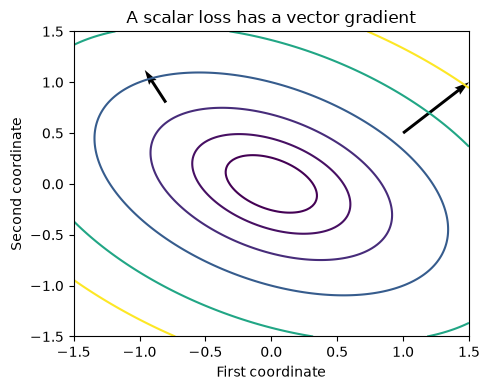

In [2]:
demo_t = np.linspace(-1.5, 1.5, 160)
demo_u, demo_v = np.meshgrid(demo_t, demo_t)
demo_quadratic = (2 * demo_u**2 + 2 * demo_u * demo_v + 3 * demo_v**2) / 2
fig, ax = plt.subplots(figsize=(5, 4))
ax.contour(demo_u, demo_v, demo_quadratic, levels=[.1, .3, .7, 1.5, 3, 5])
ax.quiver([1., -.8], [.5, .8], [2.5, -.8], [2.5, 1.6], angles="xy", scale_units="xy", scale=5)
ax.set(xlabel="First coordinate", ylabel="Second coordinate",
       title="A scalar loss has a vector gradient")
fig.tight_layout()
plt.show()

### Exercise 00.01.11 — Sweep the perturbation size

**Type:** Experimental · **Answer:** Code

Use $f(t)=(\sin t_1+t_2^2,\ \exp(0.3t_1-t_2))^T$ at $(0.4,-0.2)^T$. Compare numerical Jacobians for steps from $10^{-1}$ to $10^{-8}$ against the analytical Jacobian and plot maximum absolute error.

**Expected outcome:** A reproducible curve with approximation/roundoff interpretation, not an assumption that smaller always wins.

In [ ]:
# Your code for Exercise 00.01.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.11**

Differentiate the exponential's argument as well as the exponential.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.11**

Use `finite_jacobian` from 00.01.08. The analytical matrix is derived independently of that checker.

~~~python
reference_point = np.array([.4, -.2])
reference_smooth = lambda t: np.array([np.sin(t[0]) + t[1]**2, np.exp(.3*t[0] - t[1])])
reference_e = np.exp(.3 * reference_point[0] - reference_point[1])
reference_exact = np.array([[np.cos(.4), -.4], [.3 * reference_e, -reference_e]])
reference_steps = np.logspace(-1, -8, 8)
reference_errors = [
    np.max(np.abs(finite_jacobian(reference_smooth, reference_point, h) - reference_exact))
    for h in reference_steps
]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(reference_steps, np.maximum(reference_errors, 1e-18), "o-")
ax.set(xlabel="Central-difference step", ylabel="Maximum absolute error",
       title="Approximation and floating-point subtraction interact")
fig.tight_layout()
plt.show()
print(list(zip(reference_steps, reference_errors)))
~~~

Large steps can reflect nonlinear curvature; tiny steps can amplify subtraction error. The lowest observed error depends on the function and state. A fixed tolerance should account for the scale and inspect absolute error when derivatives are near zero.

</details>

### Exercise 00.01.12 — Visualize the cost of a shape mistake

**Type:** Experimental · **Answer:** Code

Compare correct residuals with an accidentally broadcast residual matrix for five matching predictions and targets. Plot the incorrect comparisons and estimate the bytes that the same mistake would require for 100,000 observations in float64, without allocating that large array.

**Expected outcome:** A visual explanation, correct/incorrect losses, and a bounded-memory estimate.

In [ ]:
# Your code for Exercise 00.01.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.12**

The mistake creates $n^2$ values, each eight bytes in float64.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.12**

This experiment uses only a five-by-five array. It calculates the larger allocation from dimensions rather than attempting it.

~~~python
reference_y = np.arange(5, dtype=float)
reference_correct = reference_y - reference_y
reference_wrong = reference_y[:, None] - reference_y
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(reference_wrong, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="Prediction i minus target j")
ax.set(xlabel="Target index j", ylabel="Prediction index i",
       title="Only the diagonal pairs the same observations")
fig.tight_layout()
plt.show()
print("Correct MSE:", np.mean(reference_correct**2))
print("Incorrect MSE:", np.mean(reference_wrong**2))
print("100,000 squared entries, float64 bytes:", 100_000**2 * 8)
assert np.mean(reference_correct**2) == 0
assert np.mean(reference_wrong**2) == 4
~~~

The estimated 80,000,000,000 bytes is about 74.5 GiB for the result alone. This exceeds the target laptop's memory even before temporary arrays. Broadcasting an input need not copy it, but the arithmetic result can still be enormous.

</details>

## 7. Interpretation and critical analysis

### Exercise 00.01.13 — Interpret an apparently successful gradient check

**Type:** Critical · **Answer:** Markdown

A backward pass agrees with finite differences at zero-initialized parameters on one example. Give a plan to investigate missing gradient paths, incorrect averaging, and state mutation.

**Expected outcome:** Several tests whose outcomes distinguish the suspected failures.

**Your response to Exercise 00.01.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.13**

Use nonzero states and different batch sizes, and compare parameter snapshots.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.13**

Check several nonzero smooth states so missing contributions do not all vanish. Compare against an independently written scalar objective; agreeing with a loss that shares the same wrong reduction can hide a normalization error. Repeat with one and multiple observations and inspect weights and biases separately. Save parameter copies before differentiation and assert they are unchanged afterward. A small negative-gradient step can provide additional local evidence, but does not prove global correctness or optimization success.

</details>

## 8. Review questions and knowledge checks

### Exercise 00.01.14 — Reverse an elementwise nonlinearity

**Type:** Mathematical · **Answer:** Markdown

For $A=\tanh Z$ and known scalar-loss sensitivity $G=\partial J/\partial A$, derive $\partial J/\partial Z$ entry by entry. Explain why a matrix product would be inappropriate.

**Expected outcome:** A local chain rule, matching shapes, and an explicit independence assumption.

**Your response to Exercise 00.01.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.01.14**

Each output entry depends only on the corresponding input entry.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.01.14**

$\partial A_{rs}/\partial Z_{ij}$ is zero unless $(r,s)=(i,j)$, where it is $1-\tanh^2Z_{ij}$. Thus
$$
\frac{\partial J}{\partial Z_{ij}}
=G_{ij}(1-A_{ij}^2),\qquad
\frac{\partial J}{\partial Z}=G\odot(1-A^2).
$$
Entrywise multiplication preserves the coordinates of this elementwise map. Matrix multiplication would combine coordinates through extra sums that are not dependencies of tanh. A coordinate-coupling operation requires a different local rule.

</details>

## 9. Summary and next learning steps

You have connected scalar differentials to batched arrays, distinguished Jacobians from their products, and designed numerical checks that protect shapes, scales, and state. Before proceeding, explain each reduction and reproduce a nonzero derivative check independently.

Continue with [Probability and statistics](probability-and-statistics.ipynb), then [Numerical computing](numerical-computing.ipynb). The [mathematical-audit project](../../projects/00-mathematical-audit/mathematical-audit.ipynb) integrates all three. [NumPy's broadcasting documentation](https://numpy.org/doc/stable/user/basics.broadcasting.html) is an optional implementation reference.